# Week 3 - Noise filtering
Necessary imports

In [1]:
from __future__ import annotations
import cv2
import matplotlib.pyplot as plt
import pickle
from dataclasses import dataclass
from pathlib import Path
import random, math, ast, sys
import time

import pandas as pd
import numpy as np
from skimage.feature import local_binary_pattern
from skimage.filters import threshold_otsu
from sklearn.metrics import balanced_accuracy_score, precision_score, recall_score
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

In [2]:
def find_project_root():
    for directory in (Path.cwd(), *Path.cwd().parents):
        if (directory / "data").is_dir() and (directory / "src").is_dir():
            return directory
    raise FileNotFoundError("Could not find the project root")


ROOT = find_project_root()
DATA_DIR = ROOT / "data"

## 0. Image and ground truth loading
Code snippet from week1 code so it stays with a persistent method

In [3]:
@dataclass(frozen=True)
class ImageDataset:
    """Image paths paired with integer IDs in deterministic filename order."""

    paths: tuple[Path, ...]
    ids: np.ndarray

    def __len__(self) -> int:
        return len(self.paths)


def image_id(path: Path) -> int:
    """Parse IDs from both `00012.jpg` and `bbdd_00012.jpg`."""
    return int(path.stem.rsplit("_", 1)[-1])


def load_image_dataset(directory: str | Path) -> ImageDataset:
    directory = Path(directory)
    # Sorting is essential: submission row i must correspond to query image i.
    paths = tuple(sorted(directory.glob("*.jpg")))
    if not paths:
        raise FileNotFoundError(f"No JPG images found in {directory}")
    ids = np.asarray([image_id(path) for path in paths], dtype=int)
    if len(np.unique(ids)) != len(ids):
        raise ValueError(f"Duplicate image IDs found in {directory}")
    return ImageDataset(paths=paths, ids=ids)


def load_ground_truth(path: str | Path) -> list[list[int]]:
    with Path(path).open("rb") as stream:
        values = pickle.load(stream)
    return [[int(image_id) for image_id in relevant] for relevant in values]


In [4]:
train_dataset = load_image_dataset(f"{DATA_DIR}/qsd1_w4")
non_augmented_data = load_image_dataset(f"{DATA_DIR}/qsd1_w4/non_augmented")
ground_truth = load_ground_truth(f"{DATA_DIR}/qsd1_w4/gt_corresps.pkl")

In [5]:
train_dataset.ids

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29])

## Image analysis

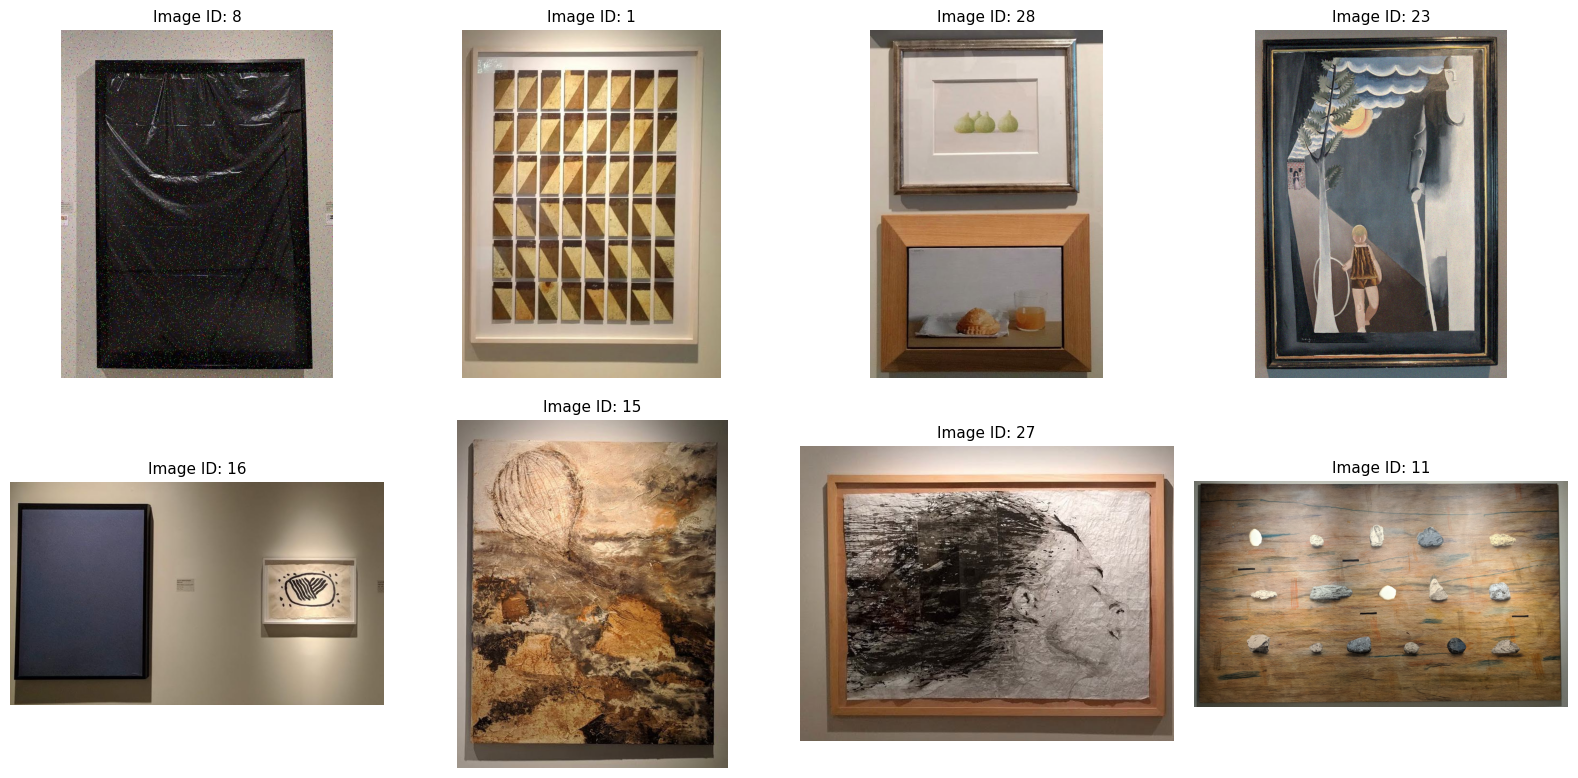

In [6]:
random.seed(52)
n_images = 8

n_cols = 4 
n_rows = math.ceil(n_images / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(n_cols * 4, n_rows * 4)
)

# Make axes iterable even if there's only one row or column
axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

for i in range(n_images):
    random_index = random.randint(0, len(train_dataset.paths) - 1)
    image_path = train_dataset.paths[random_index]
    image_id_value = train_dataset.ids[random_index]

    # Load image and convert BGR to RGB
    image = cv2.imread(str(image_path))
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    axes[i].imshow(image_rgb)
    axes[i].set_title(f"Image ID: {image_id_value}", fontsize=11)
    axes[i].axis("off")

# Hide unused grid cells
for j in range(n_images, len(axes)):
    axes[j].axis("off")

plt.tight_layout(pad=1.5)
plt.show()


## Creating and fitting the noise detector

On the last exercise the noise was analized and found but a detector was not build, in this code block a detector for the impulse type noise is built and fitted onto the training set images of week 4 (**qsd1_w4**). After finding the thresholds the denoising function can be applied to all of the images to classify and denoise them before the feature extraction process. 

noisy images: 21 / 30
Impulse detector: tp=30, tf=0.1%, balanced acc=0.762


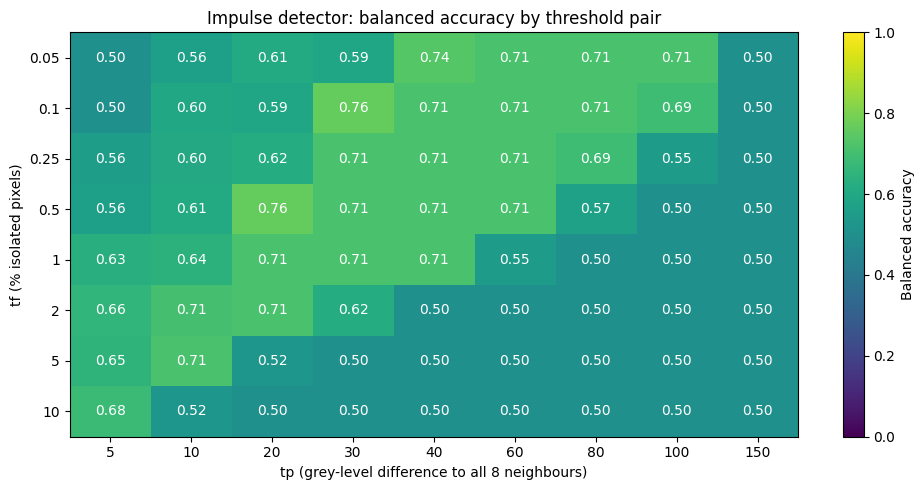

Sigma threshold: inf  |  combined balanced acc=0.762, precision=1.000, recall=0.524
11/21 noisy images detected, 0/9 false alarms on clean images


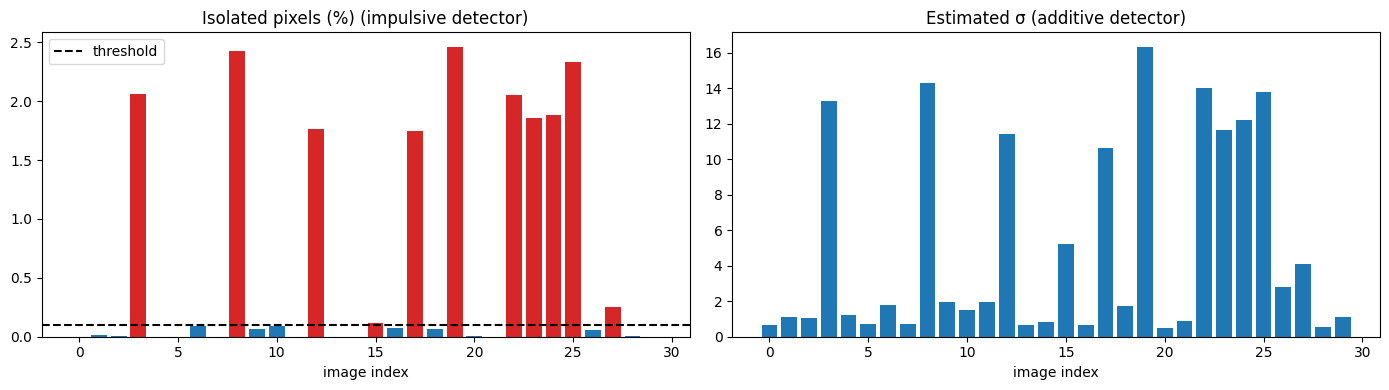

In [7]:
# 1. Detectors

def isolated_map(gray):
    """Min absolute difference to the 8 neighbours.
    A pixel is 'isolated' if this value > tp (differs from ALL neighbours)."""
    g = gray.astype(np.int16)
    p = cv2.copyMakeBorder(g, 1, 1, 1, 1, cv2.BORDER_REFLECT)
    h, w = g.shape
    m = None
    for dy in (-1, 0, 1):
        for dx in (-1, 0, 1):
            if dy == 0 and dx == 0:
                continue
            d = np.abs(g - p[1 + dy:1 + dy + h, 1 + dx:1 + dx + w])
            m = d if m is None else np.minimum(m, d)
    return m

def estimate_sigma(gray):
    """Immerkaer (1996) fast noise-sigma estimate."""
    k = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], dtype=np.float64)
    conv = cv2.filter2D(gray.astype(np.float64), -1, k, borderType=cv2.BORDER_REFLECT)
    h, w = gray.shape
    return np.sqrt(np.pi / 2) / (6 * (w - 2) * (h - 2)) * np.abs(conv[1:-1, 1:-1]).sum()

# 2. Labels + cached features (same data loading as before)

clean_by_id = dict(zip(non_augmented_data.ids.tolist(), non_augmented_data.paths))
missing_ids = sorted(set(train_dataset.ids.tolist()) - set(clean_by_id))
if missing_ids:
    raise ValueError(f"Missing non-augmented images for IDs: {missing_ids}")

noise_labels, iso_maps, sigmas = [], [], []
train_images, clean_images = [], []
for train_path, image_id_value in zip(train_dataset.paths, train_dataset.ids):
    train_image = cv2.imread(str(train_path), cv2.IMREAD_COLOR)
    clean_image = cv2.imread(str(clean_by_id[int(image_id_value)]), cv2.IMREAD_COLOR)
    if train_image is None or clean_image is None:
        raise ValueError(f"Could not read image pair for ID {image_id_value}")
    if train_image.shape != clean_image.shape:
        raise ValueError(f"Shape mismatch for ID {image_id_value}: "
                         f"{train_image.shape} vs {clean_image.shape}")
    gray = cv2.cvtColor(train_image, cv2.COLOR_BGR2GRAY)
    noise_labels.append(not np.array_equal(train_image, clean_image))
    iso_maps.append(isolated_map(gray))
    sigmas.append(estimate_sigma(gray))
    train_images.append(train_image)
    clean_images.append(clean_image)

noise_labels = np.asarray(noise_labels, dtype=bool)
sigmas = np.asarray(sigmas)
print(f"noisy images: {noise_labels.sum()} / {len(noise_labels)}")


# 3. Gridsearch: impulse detector (tp = grey-level difference, tf = % isolated pixels)
tps = [5, 10, 20, 30, 40, 60, 80, 100, 150]
tfs = [0.05, 0.1, 0.25, 0.5, 1, 2, 5, 10]          # percent of pixels

grid = np.empty((len(tfs), len(tps)))
for tp_i, tp in enumerate(tps):
    iso_pct = np.array([100 * np.mean(m > tp) for m in iso_maps])
    for tf_i, tf in enumerate(tfs):
        grid[tf_i, tp_i] = balanced_accuracy_score(noise_labels, iso_pct > tf)

tf_i, tp_i = np.unravel_index(np.argmax(grid), grid.shape)
best_tp, best_tf = tps[tp_i], tfs[tf_i]
iso_pct = np.array([100 * np.mean(m > best_tp) for m in iso_maps])
impulse_flag = iso_pct > best_tf
print(f"Impulse detector: tp={best_tp}, tf={best_tf}%, "
      f"balanced acc={grid[tf_i, tp_i]:.3f}")

# Heatmap (same as before)
fig, ax = plt.subplots(figsize=(10, 5))
hm = ax.imshow(grid, cmap="viridis", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(tps)), labels=[str(t) for t in tps])
ax.set_yticks(range(len(tfs)), labels=[str(t) for t in tfs])
ax.set_xlabel("tp (grey-level difference to all 8 neighbours)")
ax.set_ylabel("tf (% isolated pixels)")
ax.set_title("Impulse detector: balanced accuracy by threshold pair")
for i in range(len(tfs)):
    for j in range(len(tps)):
        ax.text(j, i, f"{grid[i, j]:.2f}", ha="center", va="center", color="white")
fig.colorbar(hm, ax=ax, label="Balanced accuracy")
fig.tight_layout()
plt.show()


# 4. Gridsearch: additive detector (sigma threshold), combined with OR
sigma_thresholds = [np.inf, 20, 16, 12, 10, 8, 6, 4, 2]
sigma_scores = [balanced_accuracy_score(noise_labels, impulse_flag | (sigmas > s))
                for s in sigma_thresholds]
best_sigma = sigma_thresholds[int(np.argmax(sigma_scores))]
additive_flag = sigmas > best_sigma
predicted_noise = impulse_flag | additive_flag

print(f"Sigma threshold: {best_sigma}  |  combined balanced acc="
      f"{balanced_accuracy_score(noise_labels, predicted_noise):.3f}, "
      f"precision={precision_score(noise_labels, predicted_noise):.3f}, "
      f"recall={recall_score(noise_labels, predicted_noise):.3f}")
print(f"{(predicted_noise & noise_labels).sum()}/{noise_labels.sum()} noisy images detected, "
      f"{(predicted_noise & ~noise_labels).sum()}/{(~noise_labels).sum()} false alarms on clean images")

# Slide-style bar charts (red = detector fires)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
idx = np.arange(len(noise_labels))
axes[0].bar(idx, iso_pct, color=np.where(impulse_flag, "tab:red", "tab:blue"))
axes[0].axhline(best_tf, color="k", ls="--", label="threshold")
axes[0].set(title="Isolated pixels (%) (impulsive detector)", xlabel="image index")
axes[0].legend()
axes[1].bar(idx, sigmas, color=np.where(additive_flag, "tab:red", "tab:blue"))
if np.isfinite(best_sigma):
    axes[1].axhline(best_sigma, color="k", ls="--", label="threshold")
    axes[1].legend()
axes[1].set(title="Estimated σ (additive detector)", xlabel="image index")
fig.tight_layout()
plt.show()

In [8]:
print(f"Best parameters: tp={best_tp}, tf={best_tf}, sigma_thr={best_sigma}")

Best parameters: tp=30, tf=0.1, sigma_thr=inf


In [ ]:
def denoise_if_nosiy(img_bgr,
                     tp=best_tp,              # grey-level difference to all 8 neighbours
                     tf=best_tf,              # % of isolated pixels that triggers filtering
                     sigma_thr=best_sigma,    # additive-noise threshold (np.inf = disabled)
                     ksize=3,                 # median kernel size
                     return_info=False):
    """Apply a median filter only if the image is detected as noisy.

    An image is noisy if the impulse detector OR the additive detector fires.
    """
    if img_bgr is None:
        raise ValueError("Input image is None")

    gray = img_bgr if img_bgr.ndim == 2 else cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    iso_pct = 100 * np.mean(isolated_map(gray) > tp)
    sigma = estimate_sigma(gray) if np.isfinite(sigma_thr) else 0.0

    impulse = iso_pct > tf
    additive = sigma > sigma_thr
    is_noisy = bool(impulse or additive)

    out = cv2.medianBlur(img_bgr, ksize) if is_noisy else img_bgr

    if return_info:
        return out, {"noisy": is_noisy, "isolated_pct": float(iso_pct),
                     "sigma": float(sigma), "impulse": bool(impulse),
                     "additive": bool(additive)}
    return out

Denoising info: {'noisy': True, 'isolated_pct': 2.049154859557544, 'sigma': 0.0, 'impulse': True, 'additive': False}


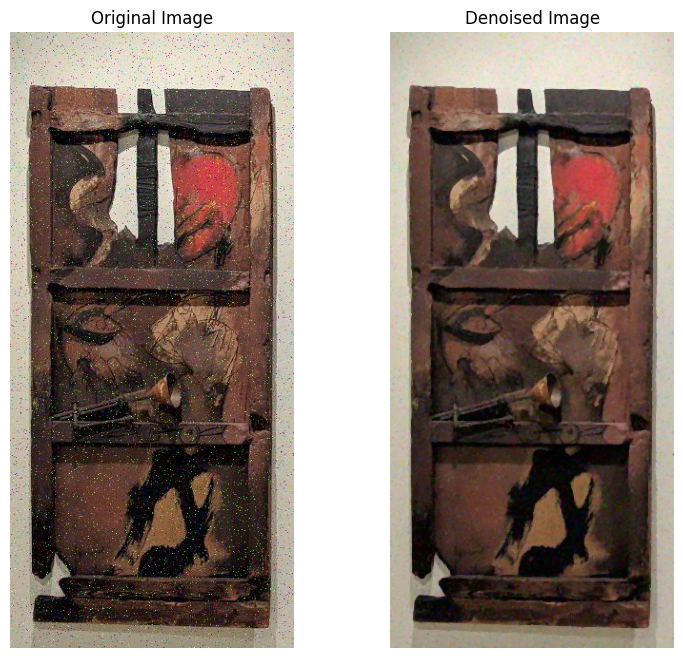

In [10]:
image = cv2.imread(str(train_dataset.paths[22]))

gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

denoised_image, info = denoise_if_nosiy(image, tp=best_tp, tf=best_tf, sigma_thr=best_sigma, ksize=3, return_info=True)
print(f"Denoising info: {info}")
# plot the comparison of the original grayscale image and the roadmap

plt.figure(figsize=(9, 8))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB), cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(denoised_image, cv2.COLOR_BGR2RGB))
plt.title("Denoised Image")
plt.axis("off")

# plt.tight_layout()
plt.show()


In [14]:
PROJECT_ROOT = ROOT
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.segmentation import foreground_mask
from src.background_removal import detect_painting_mask

In [23]:
def _boxes_are_near(box_a, box_b, gap):
    xa, ya, wa, ha = box_a
    xb, yb, wb, hb = box_b
    return not (xa + wa + gap < xb or xb + wb + gap < xa
                or ya + ha + gap < yb or yb + hb + gap < ya)
    
def keypoints_to_array(keypoints, x_offset=0, y_offset=0):
    """Nx7 array; coordinates are shifted back to the original image frame."""
    return np.array([
        [
            kp.pt[0] + x_offset, kp.pt[1] + y_offset,
            kp.size, kp.angle,
            kp.response, kp.octave,
            kp.class_id,
        ]
        for kp in keypoints
    ], dtype=np.float32).reshape(-1, 7)

def detect_painting_mask(image, max_paintings=2, component_min_area=0.005,
                         painting_min_area=0.02, merge_gap_fraction=0.04,
                         use_edges=True):
    """Combined mask + up to `max_paintings` left-to-right regions (rotated boxes).

    Foreground = colour segmenter OR edge cue (catches low-contrast paintings).
    """
    # 1. colour segmentation (ignore it if it fell back to "whole image")
    raw_mask = foreground_mask(image, min_area=component_min_area, keep="all")
    if raw_mask.mean() > 0.98:
        raw_mask = np.zeros_like(raw_mask)

    # 2. edge cue, unioned with the colour mask
    if use_edges:
        edge = edge_foreground(image)
        if edge.mean() <= 0.9:                  # skip on textured walls
            raw_mask = raw_mask | edge

    count, labels, stats, _ = cv2.connectedComponentsWithStats(
        raw_mask.astype(np.uint8), connectivity=8)

    image_area = raw_mask.size
    component_ids = [l for l in range(1, count)
                     if stats[l, cv2.CC_STAT_AREA] >= component_min_area * image_area]

    # 3. merge nearby components (union-find)
    parent = {l: l for l in component_ids}

    def find(l):
        while parent[l] != l:
            parent[l] = parent[parent[l]]
            l = parent[l]
        return l

    def union(a, b):
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[rb] = ra

    merge_gap = merge_gap_fraction * min(raw_mask.shape)
    for i, la in enumerate(component_ids):
        box_a = tuple(int(v) for v in stats[la, :4])
        for lb in component_ids[i + 1:]:
            if _boxes_are_near(box_a, tuple(int(v) for v in stats[lb, :4]), merge_gap):
                union(la, lb)

    groups = {}
    for l in component_ids:
        groups.setdefault(find(l), []).append(l)

    # 4. rotated bounding box per group
    regions = []
    for group_labels in groups.values():
        comp = np.isin(labels, group_labels)
        area = int(comp.sum())
        if area < painting_min_area * image_area:
            continue
        rows, cols = np.where(comp)
        pts = np.column_stack((cols, rows)).astype(np.float32)
        regions.append({"area": area, "box": cv2.boxPoints(cv2.minAreaRect(pts))})

    regions = sorted(regions, key=lambda r: r["area"], reverse=True)[:max_paintings]
    regions.sort(key=lambda r: float(r["box"][:, 0].mean()))

    combined = np.zeros(raw_mask.shape, dtype=np.uint8)
    for r in regions:
        m = np.zeros(raw_mask.shape, dtype=np.uint8)
        cv2.fillConvexPoly(m, np.round(r["box"]).astype(np.int32), 1)
        r["mask"] = m.astype(bool)
        combined |= m
    return combined.astype(bool), regions


def split_paintings(image, max_paintings=2, mask_background=True, **kwargs):
    """Drop-in replacement: list of dicts with bbox, crop, mask, polygon."""
    height, width = image.shape[:2]
    _, regions = detect_painting_mask(image, max_paintings=max_paintings, **kwargs)

    parts = []
    for r in regions:
        ys, xs = np.where(r["mask"])
        if len(xs) == 0:
            continue
        x0, x1 = int(xs.min()), int(xs.max()) + 1
        y0, y1 = int(ys.min()), int(ys.max()) + 1
        crop_mask = r["mask"][y0:y1, x0:x1].astype(np.uint8) * 255
        parts.append({
            "bbox": (x0, y0, x1, y1),
            "crop": image[y0:y1, x0:x1],
            "mask": crop_mask if mask_background else None,
            "polygon": r["box"],
        })

    if not parts:                                   # safety net: whole image
        parts.append({"bbox": (0, 0, width, height), "crop": image,
                      "mask": None, "polygon": None})
    return parts


def extract_features(dataset, method="SIFT", nfeatures=3000,
                     max_paintings=2, mask_background=True, use_edges=True):
    """
    Denoise (if noisy), split each image into paintings, extract features per painting.

    Returns {image_id: {"path": ..., "parts": [ {bbox, polygon, keypoints, descriptors}, ... ]}}
    Keypoints are in ORIGINAL image coordinates; parts are ordered left to right.
    """
    detector = create_feature_detector(method, nfeatures)
    features, total_time = {}, 0.0

    for image_path, image_id in zip(dataset.paths, dataset.ids):
        image = cv2.imread(str(image_path))
        if image is None:
            raise ValueError(f"Could not read image: {image_path}")

        image = denoise_if_nosiy(image, tp=best_tp, tf=best_tf,
                                 sigma_thr=best_sigma, ksize=3)

        parts_out = []
        for part in split_paintings(image, max_paintings, mask_background,
                                    use_edges=use_edges):
            x0, y0, _, _ = part["bbox"]
            gray = cv2.cvtColor(part["crop"], cv2.COLOR_BGR2GRAY)

            start = time.perf_counter()
            keypoints, descriptors = detector.detectAndCompute(gray, part["mask"])
            total_time += time.perf_counter() - start

            parts_out.append({
                "bbox": part["bbox"],
                "polygon": part["polygon"],
                "keypoints": keypoints_to_array(keypoints, x0, y0),
                "descriptors": descriptors,
            })
        features[int(image_id)] = {"path": str(image_path), "parts": parts_out}

    all_parts = [p for item in features.values() for p in item["parts"]]
    counts = [len(p["keypoints"]) for p in all_parts]
    multi = sum(len(item["parts"]) > 1 for item in features.values())

    print(f"Method: {method}")
    print(f"Images processed: {len(features)}  (split into several paintings: {multi})")
    print(f"Paintings processed: {len(all_parts)}")
    print(f"Total extraction time: {total_time:.2f} s")
    print(f"Mean/median keypoints per painting: {np.mean(counts):.1f} / {np.median(counts):.1f}")
    print(f"Min/max keypoints: {min(counts)}/{max(counts)}")
    return features

In [24]:
def rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def bgr_palette(n=10):
    return [tuple(int(c * 255) for c in plt.cm.tab10(i % n)[:3][::-1]) for i in range(n)]


def draw_keypoints(image, kp_array, color=(0, 255, 0), max_draw=800):
    """Draw keypoints from an Nx7 array as circles with orientation (strongest max_draw only)."""
    out = image.copy()
    if len(kp_array) > max_draw:
        kp_array = kp_array[np.argsort(-kp_array[:, 4])[:max_draw]]
    for x, y, size, angle, *_ in kp_array:
        r = max(2, int(size / 2))
        cv2.circle(out, (int(x), int(y)), r, color, 1, cv2.LINE_AA)
        a = np.deg2rad(angle)
        cv2.line(out, (int(x), int(y)),
                 (int(x + r * np.cos(a)), int(y + r * np.sin(a))), color, 1, cv2.LINE_AA)
    return out


def overlay_mask(image, mask, color=(0, 0, 255), alpha=0.45):
    out = image.copy()
    out[mask] = (out[mask] * (1 - alpha) + np.array(color) * alpha).astype(np.uint8)
    return out


def inside_mask(kp_array, mask):
    """Boolean array: which keypoints fall on True pixels of mask."""
    if len(kp_array) == 0:
        return np.zeros(0, dtype=bool)
    h, w = mask.shape
    xs = np.clip(kp_array[:, 0].astype(int), 0, w - 1)
    ys = np.clip(kp_array[:, 1].astype(int), 0, h - 1)
    return mask[ys, xs]


def visualize_pipeline(image_path, method="SIFT", nfeatures=3000,
                       max_paintings=2, mask_background=True, use_edges=True,
                       zoom_frac=0.25, save_path=None, **split_kwargs):
    detector = create_feature_detector(method, nfeatures)

    original = cv2.imread(str(image_path))
    if original is None:
        raise ValueError(f"Could not read image: {image_path}")
    h, w = original.shape[:2]
    thick = max(2, int(0.004 * max(h, w)))
    palette = bgr_palette()

    # --- A. Baseline: no denoising, no splitting ----------------------------------
    kps_a, _ = detector.detectAndCompute(cv2.cvtColor(original, cv2.COLOR_BGR2GRAY), None)
    kp_a = keypoints_to_array(kps_a)

    # --- B. Denoised, whole image ----------------------------------------------------
    denoised, info = denoise_if_nosiy(original, tp=best_tp, tf=best_tf,
                                      sigma_thr=best_sigma, ksize=3, return_info=True)
    kps_b, _ = detector.detectAndCompute(cv2.cvtColor(denoised, cv2.COLOR_BGR2GRAY), None)
    kp_b = keypoints_to_array(kps_b)

    # --- C. Segmentation masks (recomputed separately for display) ---------------------
    colour = foreground_mask(denoised, min_area=split_kwargs.get("component_min_area", 0.005),
                             keep="all")
    colour_used = colour.mean() <= 0.98
    colour_show = colour if colour_used else np.zeros_like(colour)

    edge = edge_foreground(denoised) if use_edges else np.zeros_like(colour)
    edge_used = use_edges and edge.mean() <= 0.9
    edge_show = edge if edge_used else np.zeros_like(colour)

    # --- D. Final regions (rotated boxes) and features per painting -------------------
    combined, regions = detect_painting_mask(denoised, max_paintings=max_paintings,
                                             use_edges=use_edges, **split_kwargs)
    parts = split_paintings(denoised, max_paintings, mask_background,
                            use_edges=use_edges, **split_kwargs)

    regions_view = overlay_mask(denoised, combined, (0, 200, 0), 0.30)
    per_part_view = denoised.copy()
    part_counts = []
    for i, part in enumerate(parts):
        x0, y0, _, _ = part["bbox"]
        gray = cv2.cvtColor(part["crop"], cv2.COLOR_BGR2GRAY)
        kps, _ = detector.detectAndCompute(gray, part["mask"])
        kp_arr = keypoints_to_array(kps, x0, y0)
        part_counts.append(len(kp_arr))

        color = palette[i % len(palette)]
        poly = part["polygon"]
        for view in (regions_view, per_part_view):
            if poly is not None:
                cv2.polylines(view, [np.round(poly).astype(np.int32)], True, color, thick)
            else:
                x0_, y0_, x1_, y1_ = part["bbox"]
                cv2.rectangle(view, (x0_, y0_), (x1_, y1_), color, thick)
        cv2.putText(regions_view, f"#{i}", (x0 + 10, y0 + 10 + thick * 8),
                    cv2.FONT_HERSHEY_SIMPLEX, max(0.8, w / 1000), color, thick, cv2.LINE_AA)
        per_part_view = draw_keypoints(per_part_view, kp_arr, color)

    # keypoints of the baseline that fall outside every painting (background clutter removed)
    in_paintings = inside_mask(kp_a, combined).sum() if combined.any() else len(kp_a)

    # --- E. Zoom around the first painting's centre to see the noise ----------------------
    if parts:
        bx0, by0, bx1, by1 = parts[0]["bbox"]
        cy, cx = (by0 + by1) // 2, (bx0 + bx1) // 2
    else:
        cy, cx = h // 2, w // 2
    z = max(16, int(zoom_frac * min(h, w)))
    y0z, x0z = int(np.clip(cy - z // 2, 0, max(0, h - z))), int(np.clip(cx - z // 2, 0, max(0, w - z)))
    ys, xs = slice(y0z, y0z + z), slice(x0z, x0z + z)
    zoom_orig = cv2.resize(original[ys, xs], None, fx=3, fy=3, interpolation=cv2.INTER_NEAREST)
    zoom_den = cv2.resize(denoised[ys, xs], None, fx=3, fy=3, interpolation=cv2.INTER_NEAREST)

    # --- Plot -----------------------------------------------------------------------------
    fig, axes = plt.subplots(3, 3, figsize=(18, 17))
    panels = [
        (draw_keypoints(original, kp_a, (0, 0, 255)),
         f"A. Original, whole image: {len(kp_a)} kp"),
        (draw_keypoints(denoised, kp_b, (0, 160, 0)),
         f"B. Denoised ({'filtered' if info['noisy'] else 'not filtered'}, "
         f"isolated={info['isolated_pct']:.2f}%): {len(kp_b)} kp"),
        (overlay_mask(denoised, colour_show, (0, 0, 255)),
         f"C1. Colour mask ({'used' if colour_used else 'ignored: whole-image fallback'}, "
         f"{colour.mean():.0%} of image)"),
        (overlay_mask(denoised, edge_show, (255, 0, 0)),
         f"C2. Edge mask ({'used' if edge_used else 'off/ignored'}, {edge.mean():.0%} of image)"),
        (regions_view, f"C3. Final: {len(parts)} painting(s) (colour OR edges, rotated boxes)"),
        (per_part_view, f"D. Features per painting: {part_counts}"),
        (zoom_orig, "Zoom: original (x3)"),
        (zoom_den, "Zoom: denoised (x3)"),
    ]
    for ax, (img, title) in zip(axes.ravel()[:8], panels):
        ax.imshow(rgb(img))
        ax.set_title(title, fontsize=10)
        ax.axis("off")

    # keypoint count comparison
    ax = axes.ravel()[8]
    ax.bar([0], [len(kp_a)], color="tab:red")
    ax.bar([1], [len(kp_b)], color="tab:green")
    ax.bar([2], [in_paintings], color="tab:gray")
    bottom = 0
    for i, c in enumerate(part_counts):
        col = tuple(v / 255 for v in palette[i % len(palette)][::-1])
        ax.bar([3], [c], bottom=bottom, color=col)
        bottom += c
    ax.set_xticks(range(4))
    ax.set_xticklabels(["A original", "B denoised", "A inside\npaintings", "D per painting\n(stacked)"],
                       fontsize=9)
    ax.set_ylabel("keypoints")
    ax.set_title("Keypoint counts")

    fig.suptitle(f"{Path(image_path).name}  |  {method}", fontsize=14)
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

    return {"original_kp": len(kp_a), "denoised_kp": len(kp_b),
            "original_kp_inside_paintings": int(in_paintings),
            "n_paintings": len(parts), "per_painting_kp": part_counts,
            "denoise_info": info,
            "colour_mask_used": bool(colour_used), "edge_mask_used": bool(edge_used)}

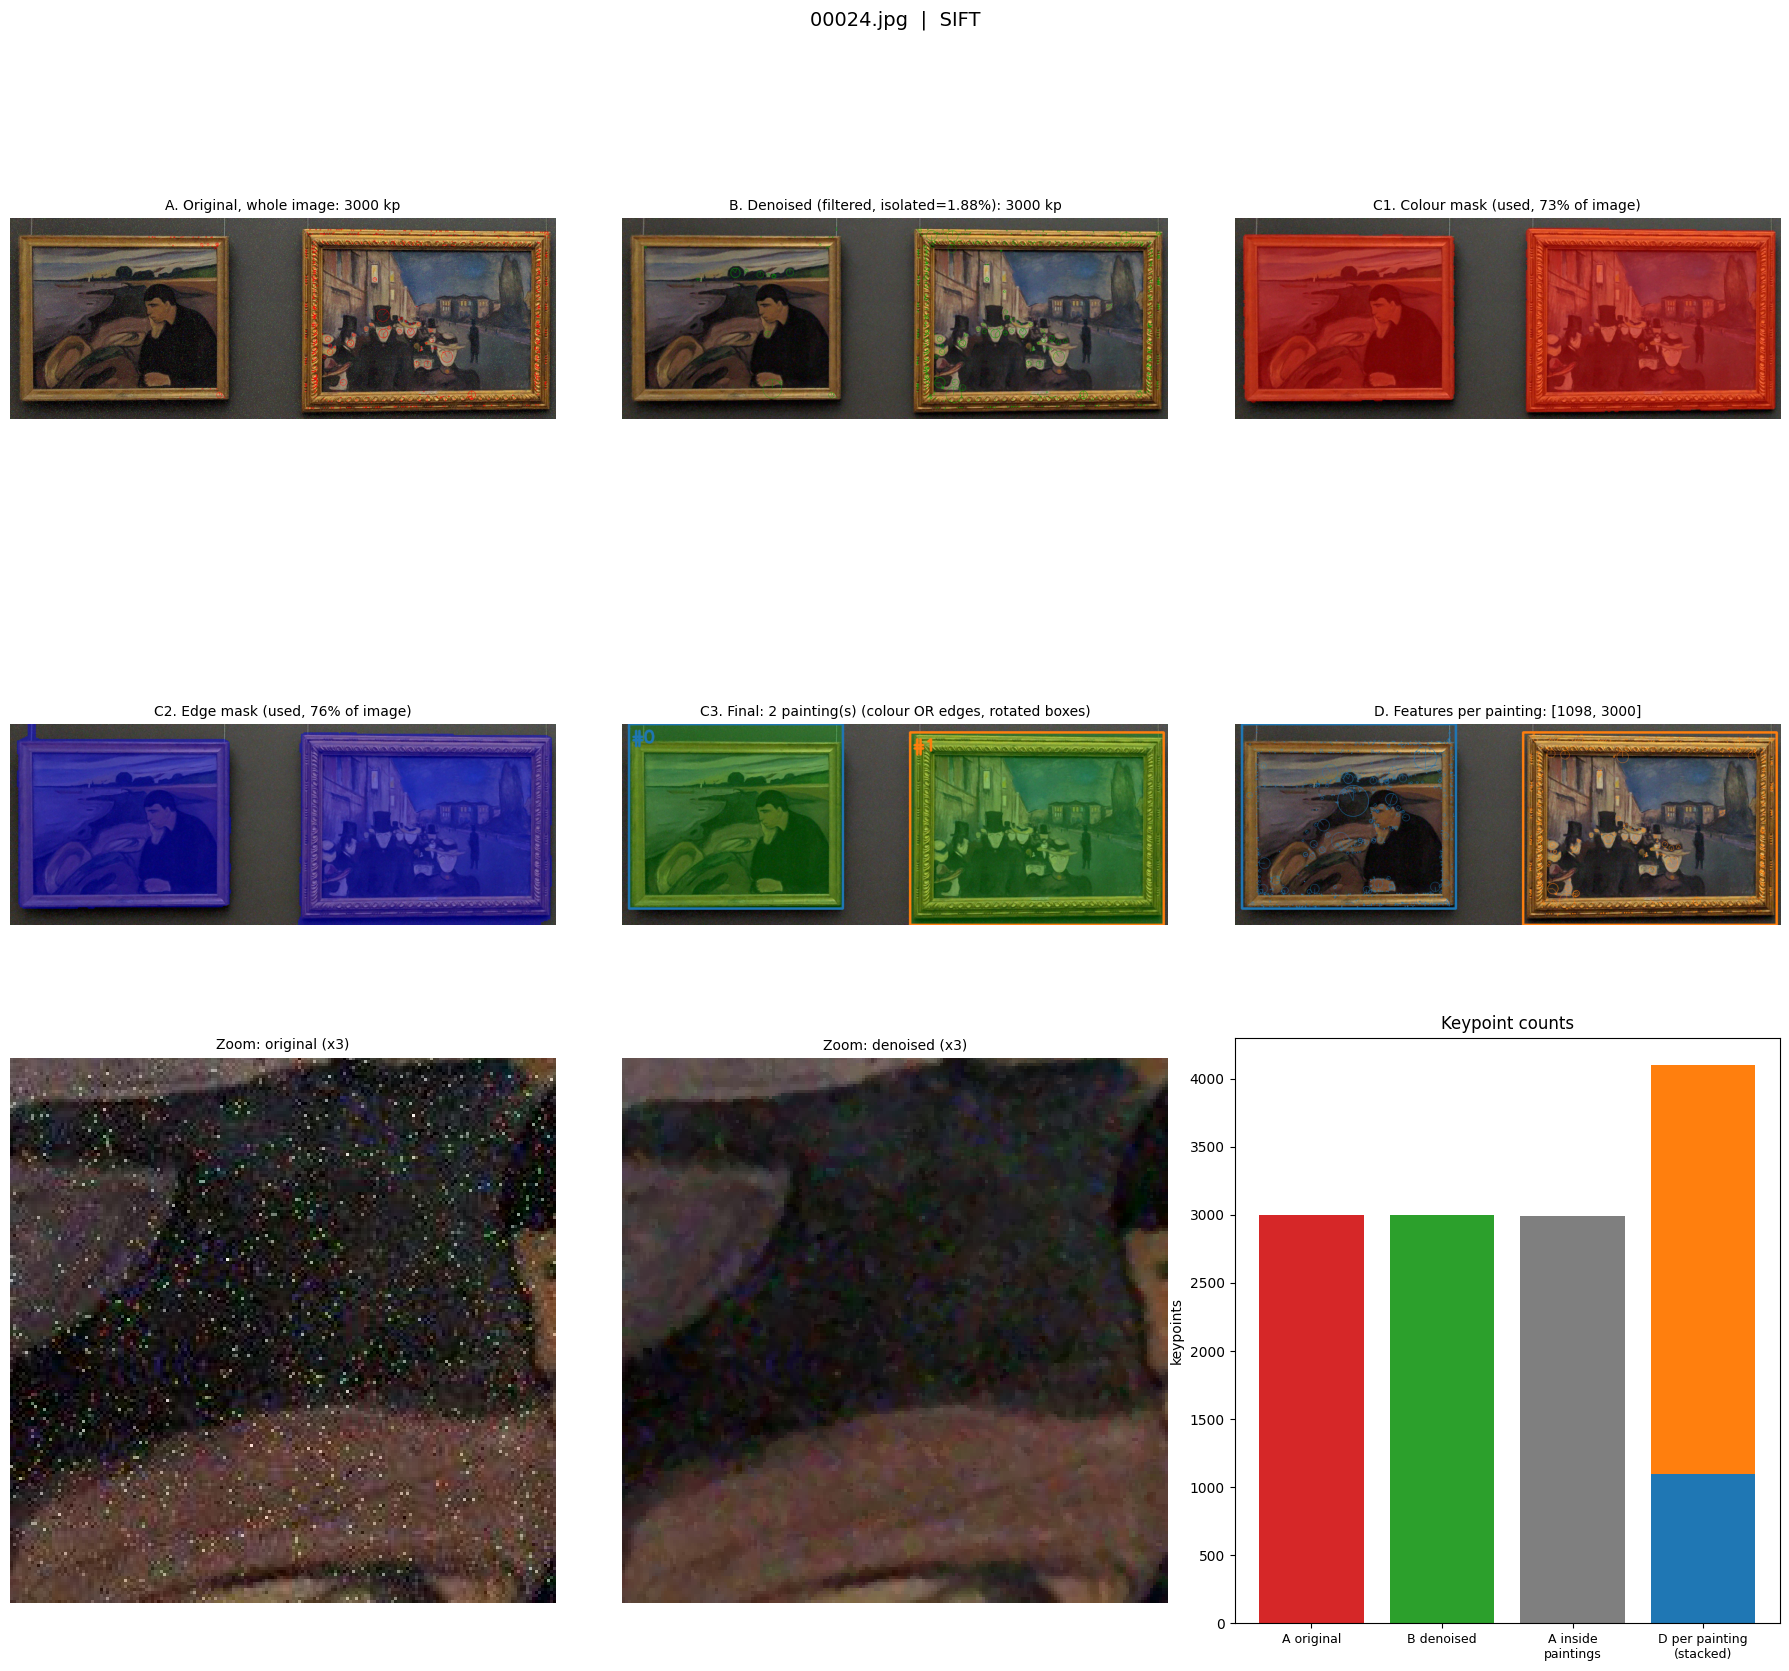

{'original_kp': 3000, 'denoised_kp': 3000, 'original_kp_inside_paintings': 2989, 'n_paintings': 2, 'per_painting_kp': [1098, 3000], 'denoise_info': {'noisy': True, 'isolated_pct': 1.8817502537845798, 'sigma': 0.0, 'impulse': True, 'additive': False}, 'colour_mask_used': True, 'edge_mask_used': True}
00002.jpg clean 2 painting(s)
00003.jpg noisy 1 painting(s)
00008.jpg noisy 1 painting(s)
00009.jpg clean 2 painting(s)
00010.jpg clean 2 painting(s)
00012.jpg noisy 1 painting(s)
00014.jpg clean 2 painting(s)
00015.jpg noisy 1 painting(s)
00016.jpg clean 2 painting(s)
00017.jpg noisy 1 painting(s)
00018.jpg clean 2 painting(s)
00019.jpg noisy 1 painting(s)
00022.jpg noisy 1 painting(s)
00023.jpg noisy 1 painting(s)
00024.jpg noisy 2 painting(s)
00025.jpg noisy 1 painting(s)
00027.jpg noisy 1 painting(s)


In [29]:
stats = visualize_pipeline(train_dataset.paths[24], method="SIFT")
print(stats)

# Two paintings close together: tighter merge gap
# visualize_pipeline(train_dataset.paths[14], merge_gap_fraction=0.02)

# Find interesting images: noisy ones and ones split into several paintings
for p in train_dataset.paths[:40]:
    img = cv2.imread(str(p))
    den, inf = denoise_if_nosiy(img, tp=best_tp, tf=best_tf, sigma_thr=best_sigma, return_info=True)
    n = len(split_paintings(den))
    if inf["noisy"] or n > 1:
        print(Path(p).name, "noisy" if inf["noisy"] else "clean", f"{n} painting(s)")